In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import jax.numpy as jnp
import equinox as eqx
import optax
import matplotlib.pyplot as plt

from pathlib import Path
from jax import random, vmap
from jax.lax import scan
from jax.tree_util import tree_map, tree_flatten
from jax.nn import gelu

%config InlineBackend.figure_format='retina'

# U-Net

The goal is the same as in the previous notebooks: to learn the solution operator $\mathcal{G}: v \longrightarrow u$ from a dataset of pairs $(v_i, u_i)$. The U-Net treats the input and the output as *images* (here, one-dimensional signals) on the same grid and maps one to the other with a convolutional network. It was introduced for the segmentation of biomedical images, and it has become a standard baseline for PDE surrogates, where the input and the output are fields on a regular grid.

### Multiscale structure

A convolution with a small kernel is a local operation, so a stack of $L$ such layers sees only $O(L)$ neighbouring points. To solve a PDE we need information from the whole domain, and the U-Net gets it by working on several scales:

- the **encoder** (the downsampling path) alternates residual blocks with *strided* convolutions that halve the number of grid points and increase the number of channels. After $d$ downsamplings one point corresponds to $2^d$ points of the original grid, so a small kernel now sees a large part of the domain;
- the **decoder** (the upsampling path) goes back to the original resolution with *transposed* convolutions that double the number of grid points and reduce the number of channels;
- the **long skip connections** concatenate the features of the encoder with the features of the decoder at the same resolution. The coarse levels know about the global structure of the solution, and the skip connections bring back the fine details lost by downsampling. The number of levels `depth` has to be chosen so that the coarsest level covers the whole domain.

### Components of our version

The basic U-Net with plain convolutions is hard to train for our problems: in our experiments it did not train at all for the diffusion equation. The following components make the training robust.

- **Residual block.** The block computes $y = Sx + \mathrm{conv}\big(\sigma(\mathrm{GN}(\mathrm{conv}(\sigma(\mathrm{GN}(x)))))\big)$, where $S$ is the identity, or a $1\times1$ convolution if the number of channels changes. The *short skip connection* $Sx$ gives the gradient a direct path to the early layers, so that the depth of the network does not make the training harder, and each block only has to learn a correction to its input.
- **Group normalisation** (GN). The channels are split into groups, and every group is normalised to zero mean and unit variance (over the grid points and the channels of the group) for each sample separately, followed by a learnable scale and shift. This keeps the magnitude of the activations the same from layer to layer, which makes the training insensitive to the initialisation and allows a larger learning rate. Unlike batch normalisation, it does not depend on the other samples of the minibatch, so the network behaves the same during training and evaluation.
- **GELU** is a smooth activation function, $\sigma(x)=x\,\Phi(x)$, where $\Phi$ is the cumulative distribution function of the standard normal distribution. The normalisation and the activation are applied *before* each convolution (the "pre-activation" form), which is the standard choice for residual networks.
- **Limited width.** In the basic U-Net the number of channels doubles at each level, which gives thousands of channels for deep networks (and most of the parameters of the model). We double the channels only up to `max_channels`, which allows a large `depth` at a moderate cost.
- **Input and output.** As in the FNO, the grid coordinates are concatenated with the input functions. The first convolution lifts the input to `N_start` channels, and the last convolution (preceded by the normalisation and the activation) maps the channels to the solution.

### Resolution

The U-Net is *fully convolutional*, so it can be applied to a grid of any size, but its kernels are tied to the grid spacing, and a network trained on one resolution is not expected to give an accurate result on another one. The datasets are redundant: if we keep every 4th point (128 points instead of 512) and restore the solution by the linear interpolation, then the relative error is about 2% for Burgers, which has shocks, and below 0.5% for the diffusion problems. This is less than the error of the networks, so we train the U-Net on the grid of 128 points, which makes the training cheaper. **Note that the errors below are computed on this coarser grid.**

*References:* O. Ronneberger, P. Fischer, T. Brox, [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597), MICCAI 2015; K. He, X. Zhang, S. Ren, J. Sun, [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385), CVPR 2016 (residual connections); Y. Wu, K. He, [Group Normalization](https://arxiv.org/abs/1803.08494), ECCV 2018; for PDEs, e.g., J. K. Gupta, J. Brandstetter, [Towards Multi-spatiotemporal-scale Generalized PDE Modeling](https://arxiv.org/abs/2209.15616), TMLR 2023; for the optimiser: D. Kingma, J. Ba, [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980), ICLR 2015.

In [2]:
class ResBlock(eqx.Module):
    norm1: eqx.Module
    conv1: eqx.Module
    norm2: eqx.Module
    conv2: eqx.Module
    skip: eqx.Module

    def __init__(self, c_in, c_out, key, kernel_size=3, groups=8):
        keys = random.split(key, 3)
        padding = kernel_size // 2
        self.norm1 = eqx.nn.GroupNorm(groups, c_in)
        self.conv1 = eqx.nn.Conv(1, c_in, c_out, kernel_size, padding=padding, key=keys[0])
        self.norm2 = eqx.nn.GroupNorm(groups, c_out)
        self.conv2 = eqx.nn.Conv(1, c_out, c_out, kernel_size, padding=padding, key=keys[1])
        # the short skip connection: 1x1 convolution if the number of channels changes
        self.skip = eqx.nn.Conv(1, c_in, c_out, 1, key=keys[2]) if c_in != c_out else eqx.nn.Identity()

    def __call__(self, x):
        h = self.conv1(gelu(self.norm1(x)))
        h = self.conv2(gelu(self.norm2(h)))
        return self.skip(x) + h

class UNet(eqx.Module):
    lift: eqx.Module
    encoder: list
    downsampling: list
    bottleneck: eqx.Module
    upsampling: list
    decoder: list
    norm: eqx.Module
    project: eqx.Module

    def __init__(self, key, depth=5, N_start=16, max_channels=128, kernel_size=3, N_in=2, N_out=1):
        padding = kernel_size // 2
        channels = [min(N_start * 2**i, max_channels) for i in range(depth)]  # channels on every level
        keys = random.split(key, 4*depth + 3)
        self.lift = eqx.nn.Conv(1, N_in, channels[0], kernel_size, padding=padding, key=keys[0])
        self.encoder = [ResBlock(channels[i], channels[i], keys[1+i], kernel_size) for i in range(depth-1)]
        self.downsampling = [eqx.nn.Conv(1, channels[i], channels[i+1], kernel_size, stride=2, padding=padding, key=keys[depth+i]) for i in range(depth-1)]
        self.bottleneck = ResBlock(channels[-1], channels[-1], keys[2*depth], kernel_size)
        self.upsampling = [eqx.nn.ConvTranspose(1, channels[i+1], channels[i], 2, stride=2, key=keys[2*depth+1+i]) for i in range(depth-1)]
        # the input of a decoder block is the concatenation of the upsampled features and the encoder features
        self.decoder = [ResBlock(2*channels[i], channels[i], keys[3*depth+1+i], kernel_size) for i in range(depth-1)]
        self.norm = eqx.nn.GroupNorm(8, channels[0])
        self.project = eqx.nn.Conv(1, channels[0], N_out, kernel_size, padding=padding, key=keys[-1])

    def __call__(self, feature, x):
        u = self.lift(jnp.concatenate([feature, x], 0))  # the coordinates are the additional input channels
        Z = []  # features of the encoder, used in the long skip connections
        for block, down in zip(self.encoder, self.downsampling):
            u = block(u)
            Z.append(u)
            u = down(u)
        u = self.bottleneck(u)
        for up, block, z in zip(self.upsampling[::-1], self.decoder[::-1], Z[::-1]):
            u = block(jnp.concatenate([up(u), z], 0))
        return self.project(gelu(self.norm(u)))

### Loss and optimisation step

The loss for a single sample is $\|u_\theta(v)-u\|_2^2$, and for a minibatch it is the average over its samples. As in the PINN tutorials, the training loop is compiled with `scan`, and the indices of the minibatches are pregenerated in advance.

In [3]:
def l2_loss(model, input, target, x):
    X = model(input, x)
    error = jnp.mean(jnp.sum(((X - target).reshape(target.shape[0], -1,))**2, axis=1))
    return error

def batch_l2_loss(model, input, target, x):
    res = vmap(l2_loss, in_axes=(None, 0, 0, None))(model, input, target, x)
    return jnp.mean(res)

l2_compute_loss_and_grads = eqx.filter_value_and_grad(batch_l2_loss)

def l2_make_step_scan(carry, n, optim):
    model, features, targets, x, opt_state = carry
    loss, grads = l2_compute_loss_and_grads(model, features[n], targets[n], x)
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, features, targets, x, opt_state], loss

def make_prediction_scan(carry, i):
    model, features, coords = carry
    prediction = model(features[i], coords)
    return carry, prediction

# Datasets

We use the datasets generated in the previous tutorials, 1000 samples each on a grid of 512 points (we use every 4th point for the U-Net, see above). The first 900 samples are used for training, and the last 100 are the test set, which is never seen by the network during the training.

| name | input $v$ | output $u$ |
|---|---|---|
| Burgers | initial condition $u_0(x)$ | solution of the Burgers equation at the final time |
| Diffusion | coefficient $a(x)$ and right-hand side $f(x)$ (two channels) | solution of $-\frac{d}{dx}\left(a(x) \frac{du(x)}{dx}\right)=f(x)$ |
| Diffusion, constant source | coefficient $a(x)$ (one channel) | solution of $-\frac{d}{dx}\left(a(x) \frac{du(x)}{dx}\right)=f(x)$ with a constant $f(x)$ |

The inputs and the outputs are divided by their maximal absolute values. The grid coordinates are passed to the network as an additional input channel.

In [4]:
# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

In [5]:
def load_dataset(dataset_name, stride=4):
    # returns arrays of shape (samples, channels, grid points), coordinates of shape (1, grid points)
    if dataset_name == 'Burgers':
        data = jnp.load(data_dir / "burgers_dataset.npz")
        features = jnp.expand_dims(data["initial condition"], 1)
    elif dataset_name == 'Diffusion':
        data = jnp.load(data_dir / "diffusion_dataset.npz")
        features = jnp.stack([data["diffusion coefficient"], data["righ-hand side"]], axis=1)
    elif dataset_name == 'Diffusion_constant_source':
        data = jnp.load(data_dir / "diffusion_dataset_2.npz")
        features = jnp.expand_dims(data["diffusion coefficient"], axis=1)
    targets = jnp.expand_dims(data["solution"], 1)
    coordinates = jnp.expand_dims(data["grid points"], 0)

    # keep every stride-th grid point
    features, targets, coordinates = features[:, :, ::stride], targets[:, :, ::stride], coordinates[:, ::stride]

    features = features / jnp.max(jnp.abs(features))
    targets = targets / jnp.max(jnp.abs(targets))
    return features, targets, coordinates

# Training

All three problems are trained with the same network and the same hyperparameters. The function `train` loads a dataset, trains the U-Net, and returns the model together with the training history and the relative errors $\|u_\theta-u\|_2/\|u\|_2$ of all samples. For the training and the test sets we report the mean, the median, the minimal and the maximal error. The median is less sensitive than the mean to a few samples with a large error, and the minimum and the maximum show the range of the quality.

We use Adam with the learning rate decaying from $10^{-3}$ to $10^{-5}$ by a cosine schedule.

In [6]:
depth = 7  # number of levels; the coarsest level has 128 / 2**(depth-1) = 2 points
N_start = 16  # number of channels on the finest level
max_channels = 128  # the number of channels is doubled on every level up to this value
N_epoch = 200
N_train = 900
N_batch = 10
learning_rate = 1e-3  # initial value
N_run = N_epoch * N_train // N_batch  # total number of updates

In [7]:
def train(dataset_name, key=random.PRNGKey(45)):
    features, targets, coordinates = load_dataset(dataset_name)
    keys = random.split(key)

    N_in = coordinates.shape[0] + features.shape[1]
    model = UNet(keys[0], depth=depth, N_start=N_start, max_channels=max_channels, N_in=N_in, N_out=targets.shape[1])
    model_size = sum(tree_map(lambda x: jnp.size(x), tree_flatten(eqx.filter(model, eqx.is_array))[0]))
    schedule = optax.cosine_decay_schedule(learning_rate, N_run, alpha=1e-2)
    optim = optax.adam(learning_rate=schedule)
    opt_state = optim.init(eqx.filter(model, eqx.is_array))
    n = random.choice(keys[1], N_train, shape=(N_run, N_batch))
    carry = [model, features, targets, coordinates, opt_state]

    make_step_scan_ = lambda carry, n: l2_make_step_scan(carry, n, optim)

    start = time.time()
    carry, history = scan(make_step_scan_, carry, n)
    history.block_until_ready()
    training_time = time.time() - start
    model = carry[0]

    # relative errors of all samples
    ind = jnp.arange(features.shape[0])
    predictions = scan(make_prediction_scan, [model, features, coordinates], ind)[1]
    errors = (jnp.linalg.norm(predictions - targets, axis=2) / jnp.linalg.norm(targets, axis=2))[:, 0]

    print(f"Number of parameters: {model_size}")
    print(f"Training time: {training_time:.1f} s")
    print("Relative error      mean    median       min       max")
    for name, e in [("train", errors[:N_train]), ("test", errors[N_train:])]:
        print(f"  {name:<12} {jnp.mean(e):9.4f} {jnp.median(e):9.4f} {jnp.min(e):9.4f} {jnp.max(e):9.4f}")
    return model, history, errors, predictions, targets, coordinates

# Visualisation

For every dataset we plot

- the **training curve**: the loss on the minibatches (light grey) and its average over an epoch (black);
- the **best and the worst samples of the test set**, ranked by the relative error: the prediction against the reference solution and the pointwise error $|u_\theta-u|/\max|u|$. The values are those of the normalised data.

The best and the worst samples correspond to the minimal and the maximal errors reported above. They show the range of the quality of the network, and the mean error alone does not: a small mean error may hide a few samples with a large error.

In [8]:
def plot_results(history, errors, predictions, targets, coordinates, figure_name=None):
    if figure_name is not None and not data_dir.exists():
        data_dir.mkdir()

    # training curve
    epochs = jnp.arange(1, N_epoch + 1)
    steps_per_epoch = N_train // N_batch
    fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
    ax.plot(epochs[0] - 1 + jnp.arange(N_run) / steps_per_epoch, history, color="lightgray", linewidth=0.5, label="minibatch")
    ax.plot(epochs, history.reshape(N_epoch, steps_per_epoch).mean(axis=1), color="black", label="epoch average")
    ax.set_yscale("log")
    ax.set_xlabel("epoch", fontsize="x-large")
    ax.set_ylabel("loss", fontsize="x-large")
    ax.legend()
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_convergence.pdf", format='pdf', bbox_inches='tight')

    # best and worst samples of the test set
    test_errors = errors[N_train:]
    selected = {"best": N_train + jnp.argmin(test_errors), "worst": N_train + jnp.argmax(test_errors)}
    x = coordinates[0]
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for row, (name, i) in zip(axes, selected.items()):
        u, u_pred = targets[i, 0], predictions[i, 0]
        row[0].plot(x, u, color="black", label="reference", linewidth=1.0)
        row[0].plot(x, u_pred, color="tab:red", dashes=[4, 4, 4, 4], label="UNet", linewidth=2.5)
        row[0].set_ylabel("$u(x)$", fontsize="x-large")
        row[0].set_title(f"{name} test sample (#{int(i)}), relative error {errors[i]:.3f}")
        row[0].legend()
        row[1].plot(x, jnp.abs(u_pred - u) / jnp.max(jnp.abs(u)), color="black")
        row[1].set_yscale("log")
        row[1].set_ylabel("$|u_\\theta - u| / \\max|u|$", fontsize="x-large")
        for ax in row:
            ax.set_xlabel("$x$", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_solutions.pdf", format='pdf', bbox_inches='tight')

## Burgers equation

Number of parameters: 1334305
Training time: 84.2 s
Relative error      mean    median       min       max


  train           0.0148    0.0143    0.0069    0.0332


  test            0.0562    0.0375    0.0163    0.2759


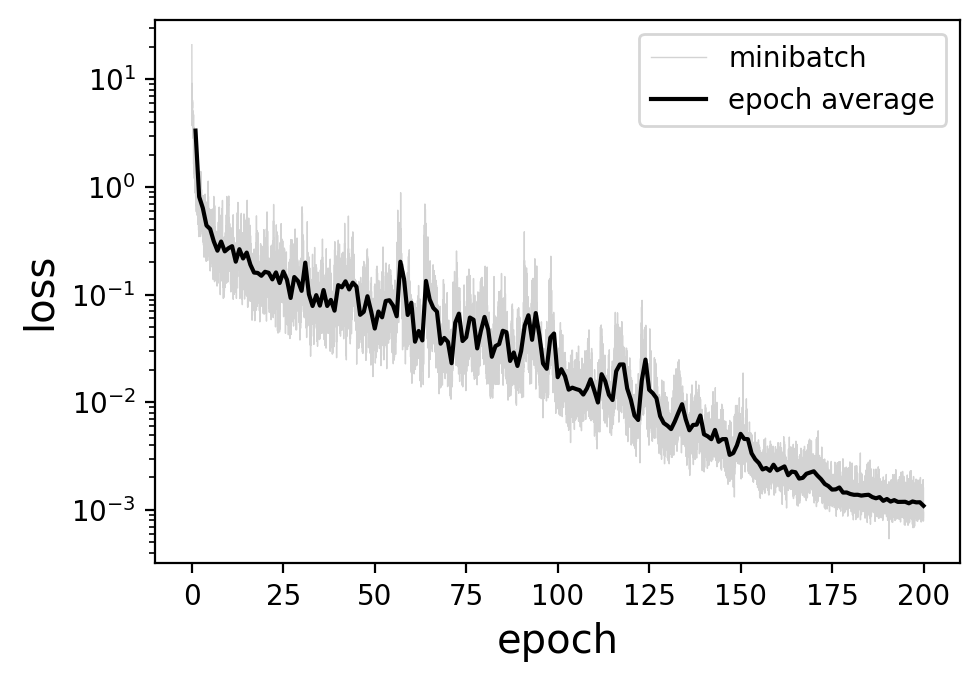

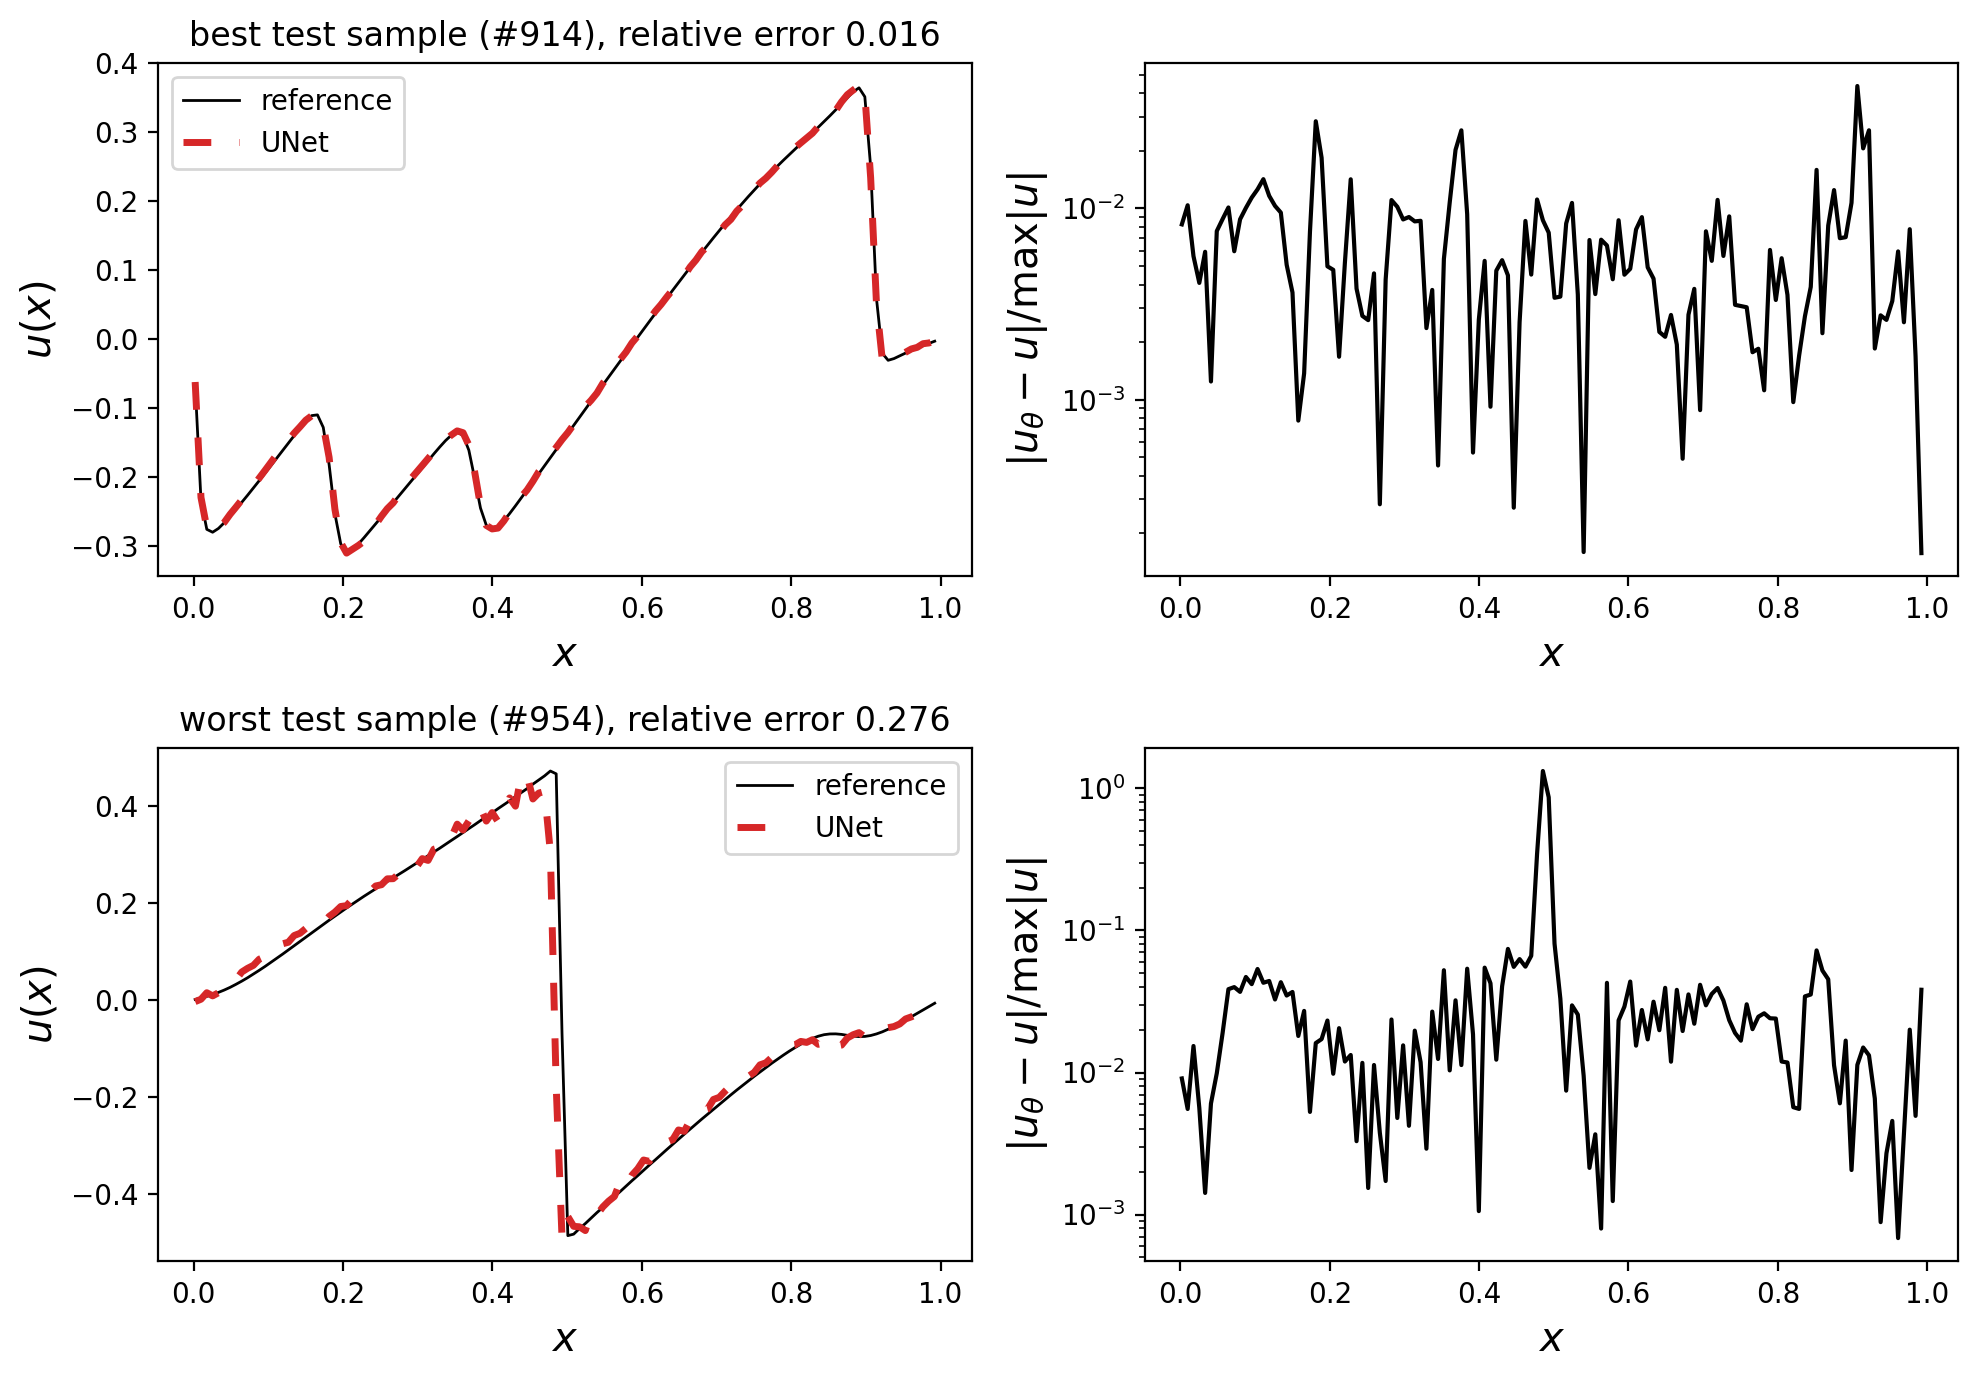

In [9]:
model, history, errors, predictions, targets, coordinates = train('Burgers')
plot_results(history, errors, predictions, targets, coordinates, figure_name='UNet_Burgers')

## Diffusion equation

Number of parameters: 1334353
Training time: 80.5 s
Relative error      mean    median       min       max
  train           0.0319    0.0190    0.0040    0.5039
  test            0.1630    0.1211    0.0257    0.8123


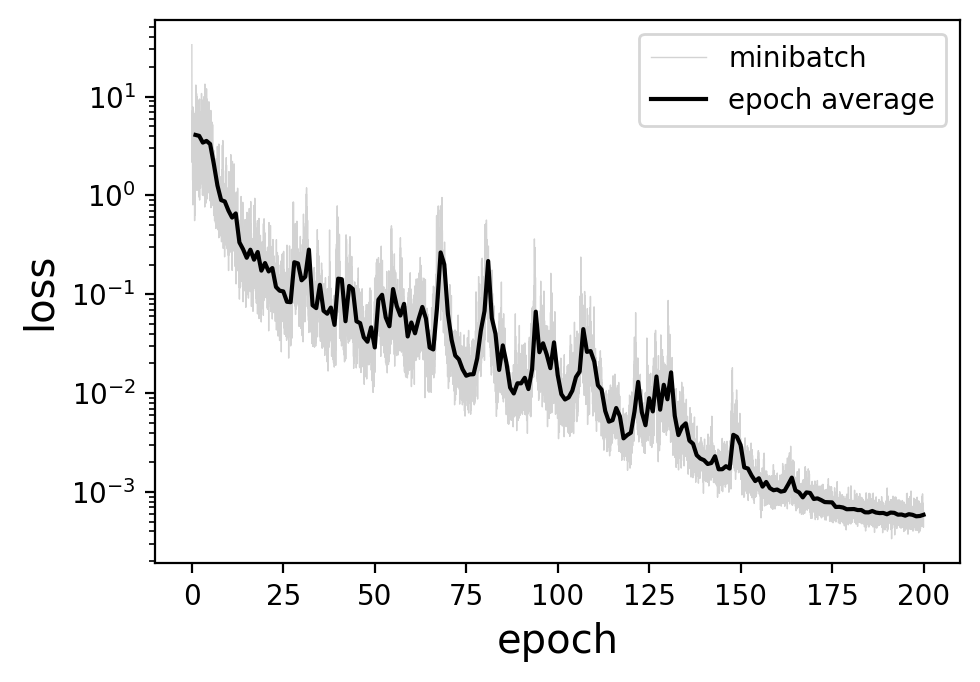

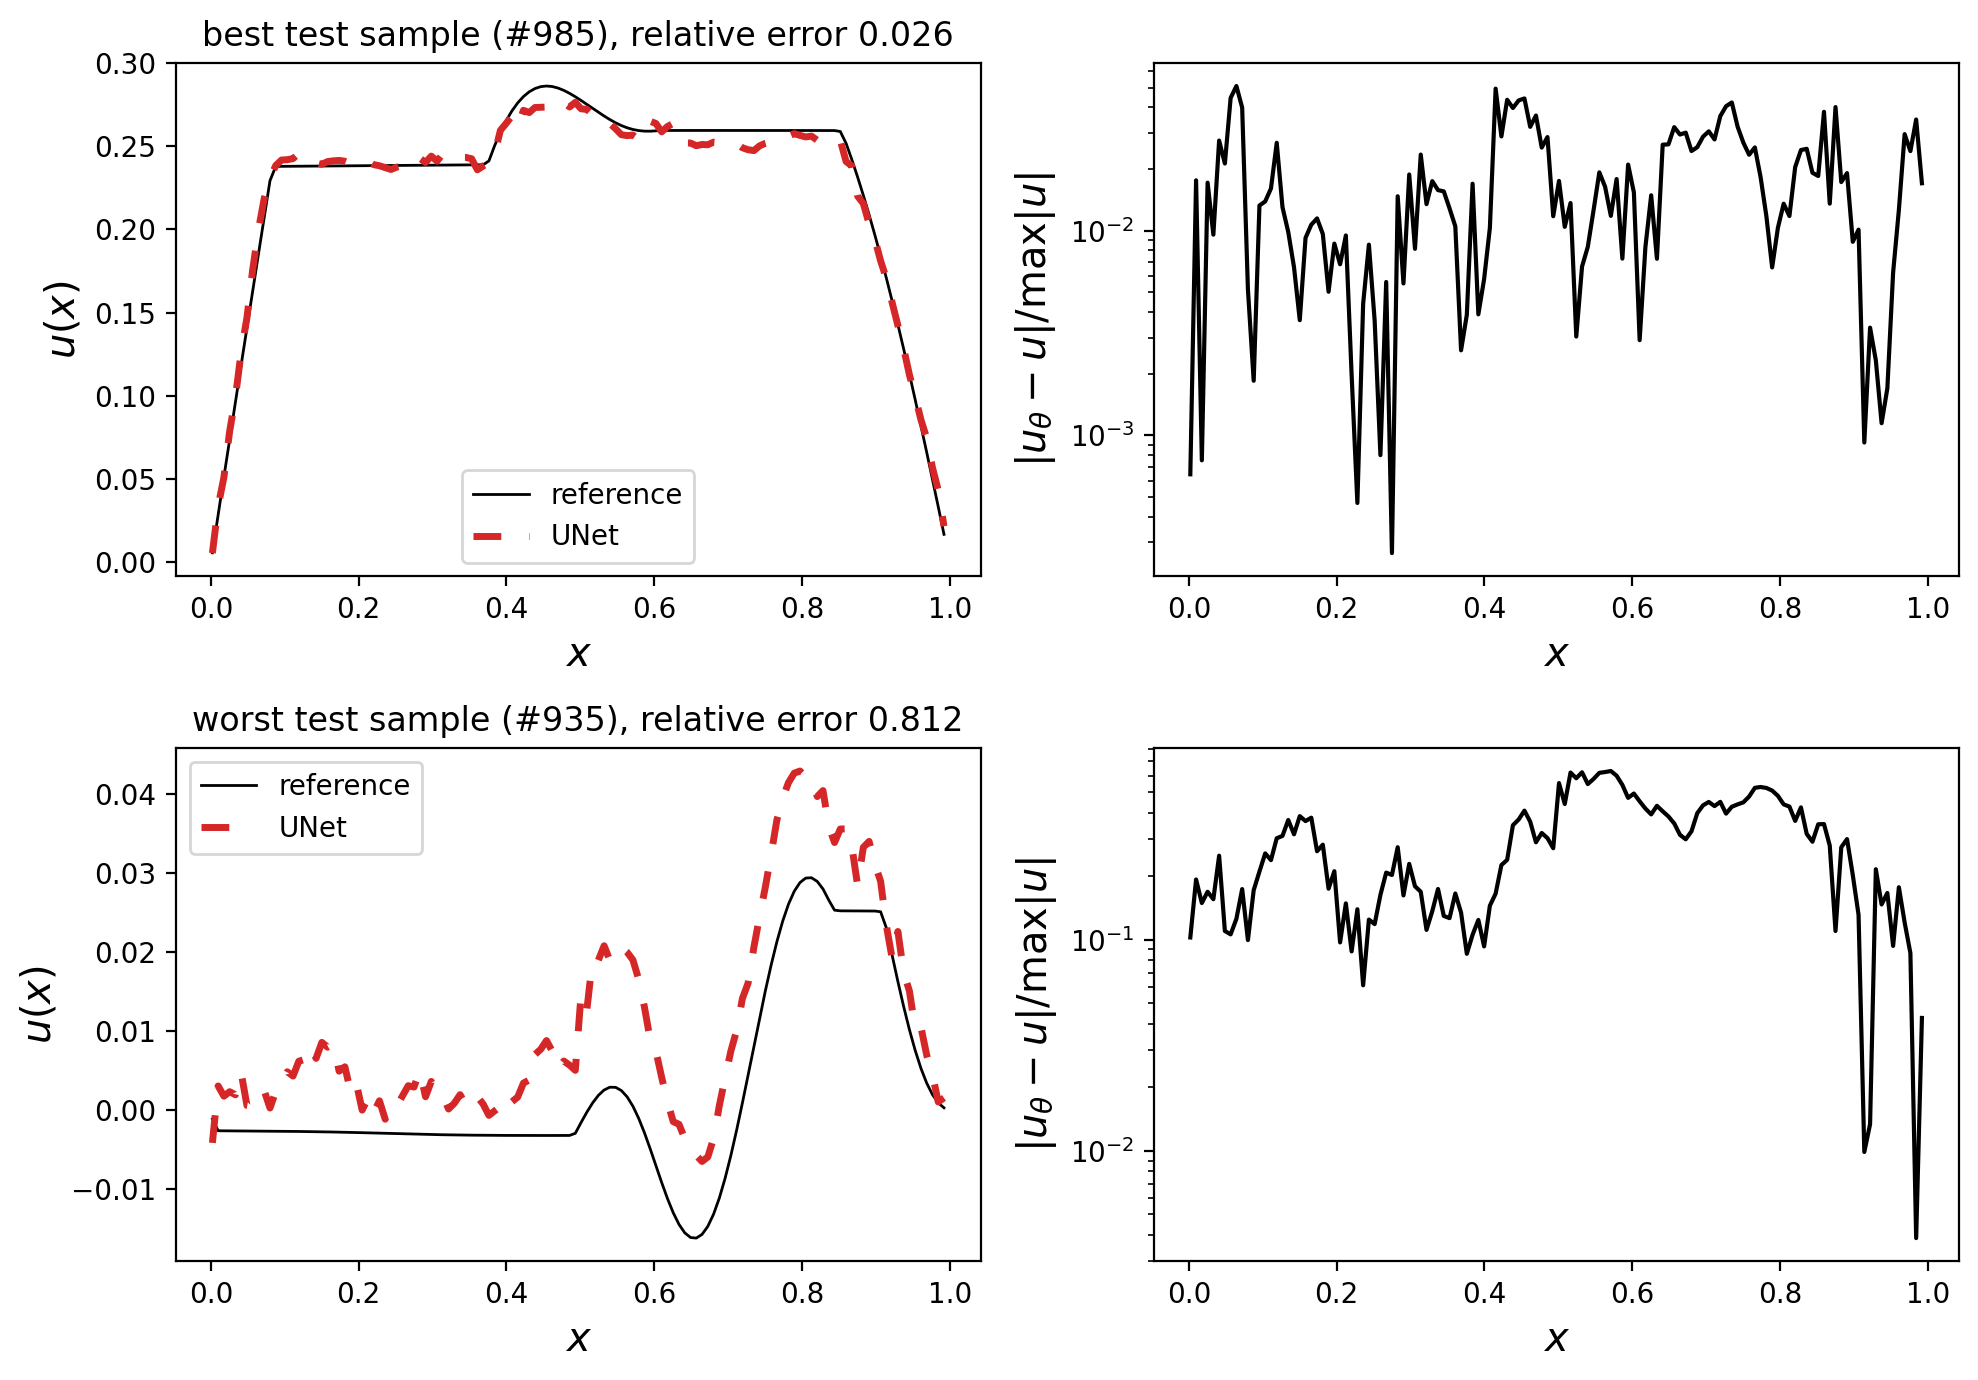

In [10]:
model, history, errors, predictions, targets, coordinates = train('Diffusion')
plot_results(history, errors, predictions, targets, coordinates, figure_name='UNet_Diffusion')

## Diffusion equation with a constant source term

The right-hand side is the same for all samples, so the only input channel is the coefficient $a(x)$.

Number of parameters: 1334305
Training time: 79.4 s
Relative error      mean    median       min       max
  train           0.0078    0.0057    0.0014    0.0594
  test            0.0445    0.0303    0.0029    0.4674


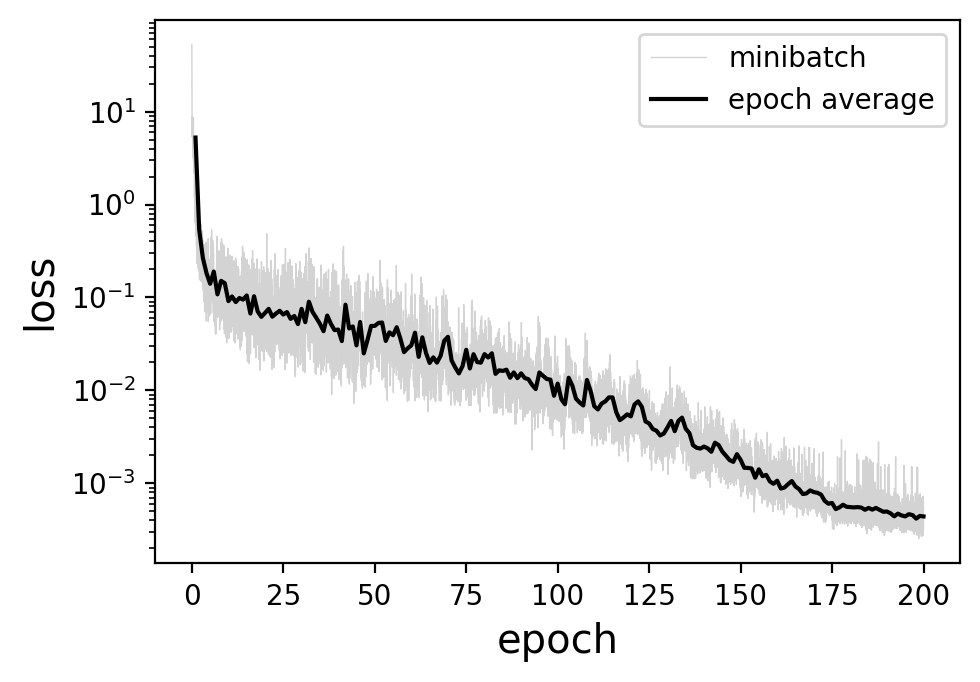

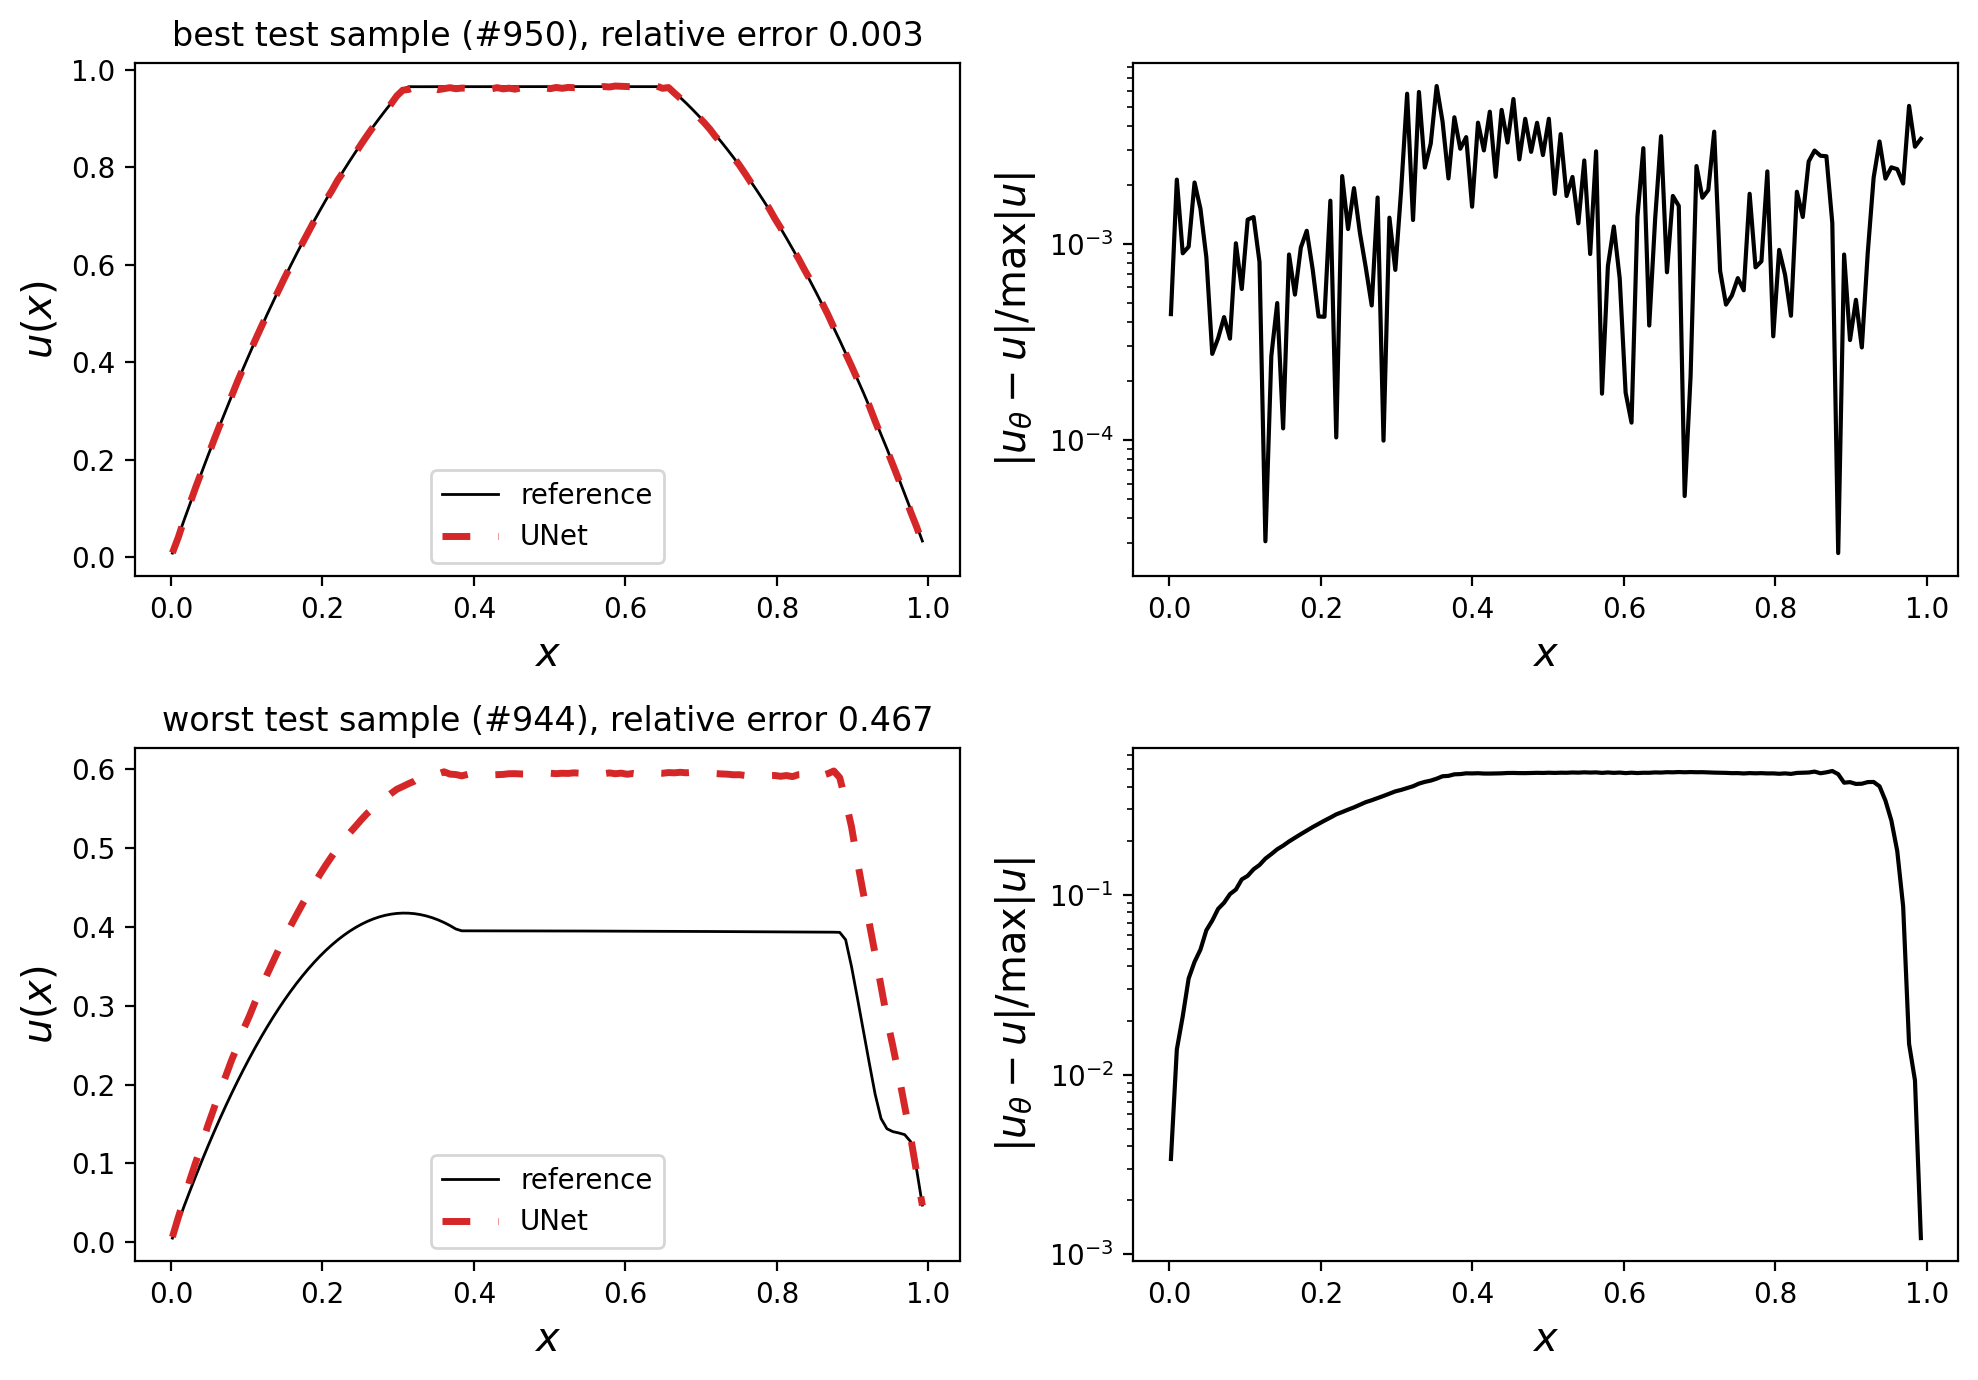

In [11]:
model, history, errors, predictions, targets, coordinates = train('Diffusion_constant_source')
plot_results(history, errors, predictions, targets, coordinates, figure_name='UNet_Diffusion_constant_source')

# Summary

Relative errors $\|u_\theta-u\|_2/\|u\|_2$ of the trained U-Net on the grid of 128 points (900 training and 100 test samples, 200 epochs, about 80 s of training for each problem):

| Dataset | Set | Mean | Median | Min | Max |
|---|---|---|---|---|---|
| Burgers | train | 0.0148 | 0.0143 | 0.0069 | 0.0332 |
| Burgers | test | 0.0562 | 0.0375 | 0.0163 | 0.2759 |
| Diffusion | train | 0.0319 | 0.0190 | 0.0040 | 0.5039 |
| Diffusion | test | 0.1630 | 0.1211 | 0.0257 | 0.8123 |
| Diffusion, constant source | train | 0.0078 | 0.0057 | 0.0014 | 0.0594 |
| Diffusion, constant source | test | 0.0445 | 0.0303 | 0.0029 | 0.4674 |

**Tuning.** The basic U-Net (plain convolutions, the number of channels doubled on every level, small initial weights) gave test mean errors of 0.48, 1.25 and 0.56 on the grid of 512 points, and it did not train at all for the diffusion equation. A short search (a validation set taken from the training set, one seed) showed that the training is fixed by the residual blocks with the group normalisation, the default initialisation, the learning rate $10^{-3}$ with a cosine decay, and limiting the number of channels. The coarser grid of 128 points made the training cheaper and, together with the depth, improved the Burgers result. A deeper network (7 levels instead of 5) was clearly better for the diffusion equation and the same within the noise for Burgers.

**Conclusion.** The modified U-Net is competitive with the FNO: the test mean error is 0.056 (FNO: 0.053) for Burgers, 0.163 (FNO: 0.147) for diffusion, and 0.045 (FNO: 0.066) for diffusion with a constant source, and it is better than the DeepONet on all problems. The diffusion equation with two input functions is again the hardest, and the worst test samples have large errors (up to 0.8). The comparison with the other two notebooks is only approximate: the U-Net was tuned more than the FNO, it is evaluated on a coarser grid, and its kernels are tied to the grid spacing, so, unlike the FNO, it is not expected to transfer to another resolution.